# Interpretação dos resíduos

**Objetivo:** entender o que o modelo final usa para prever o valor e encontrar jogadores que valem mais ou menos do que o perfil explica.

**Entrada:** `data/processado/features_contexto.csv` e `models/modelo_final.json`
**Saída:** `data/processado/residuos_jogadores.csv`, `residuos_baseline.csv` e `importancia_variaveis.csv`

**Reprodutibilidade:** a semente `SEED = 42` fica em `scripts/modelagem.py` e é usada em tudo que tem aleatoriedade (K-Fold embaralhado, target encoding, modelos de árvore, ElasticNet e importância por permutação). O GroupKFold não embaralha, então é sempre igual.

In [1]:
import sys
sys.path.append("../scripts")

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from modelagem import SEED, ALVO, BLOCOS, COLUNAS_BASE, construir_modelos_ablacao, construir_modelos_finais
from modelagem import classificar_residuo, importancia_permutacao, metricas_em_euros, previsoes_oof

df = pd.read_csv("../data/processado/features_contexto.csv")

with open("../models/modelo_final.json", encoding="utf-8") as f:
    info = json.load(f)

np.random.seed(SEED)
print("SEED:", SEED)

SEED: 42


In [2]:
nome_final = info["nome"]
params = info["hiperparametros"]
colunas = info["colunas"]

fabrica_escolhida = construir_modelos_finais()[nome_final][0]


def fabrica_final():
    return fabrica_escolhida().set_params(**params)


print("Modelo final:", nome_final, params)

Modelo final: ridge {'modelo__alpha': 0.1}


## Previsões fora da amostra

Os resíduos (log real − log previsto) são calculados com GroupKFold: cada jogador é previsto por um modelo que nunca o viu. Se usássemos o modelo treinado com toda a base, os resíduos ficariam pequenos demais e o ranking não teria valor.

In [3]:
df["log_previsto"] = previsoes_oof(df, fabrica_final, colunas)
df["valor_previsto_eur"] = np.exp(df["log_previsto"])
df["residuo_log"] = df[ALVO] - df["log_previsto"]
df["residuo_eur"] = df["valor_mercado_eur"] - df["valor_previsto_eur"]
df["razao_real_previsto"] = df["valor_mercado_eur"] / df["valor_previsto_eur"]

pd.Series(metricas_em_euros(df[ALVO].to_numpy(), df["log_previsto"].to_numpy())).round(3)

MAE_eur     1988252.471
RMSE_eur    3186820.578
R2_log            0.695
MAE_log           0.522
dtype: float64

## Efeito do clube

Comparação do resíduo médio por clube e por temporada entre o baseline (`ridge_completo`) e o modelo final. O ideal é ficar perto de zero.

In [4]:
fabrica_base = construir_modelos_ablacao()["ridge_completo"][0]
df["residuo_baseline"] = df[ALVO] - previsoes_oof(df, fabrica_base, COLUNAS_BASE)
df[["season", "player_id", "clube_temporada", "residuo_baseline"]].to_csv("../data/processado/residuos_baseline.csv", index=False)

clube = df.groupby("clube_temporada")[["residuo_baseline", "residuo_log"]].mean().sort_values("residuo_baseline")

print(f"Desvio do resíduo médio entre clubes: baseline = {clube['residuo_baseline'].std():.3f} | modelo final = {clube['residuo_log'].std():.3f}")
print()
print("Resíduo médio por temporada:")
print(df.groupby("season")[["residuo_baseline", "residuo_log"]].mean().round(3).to_string())

Desvio do resíduo médio entre clubes: baseline = 0.557 | modelo final = 0.174

Resíduo médio por temporada:


        residuo_baseline  residuo_log
season                               
2024              -0.029       -0.024
2025               0.068        0.060


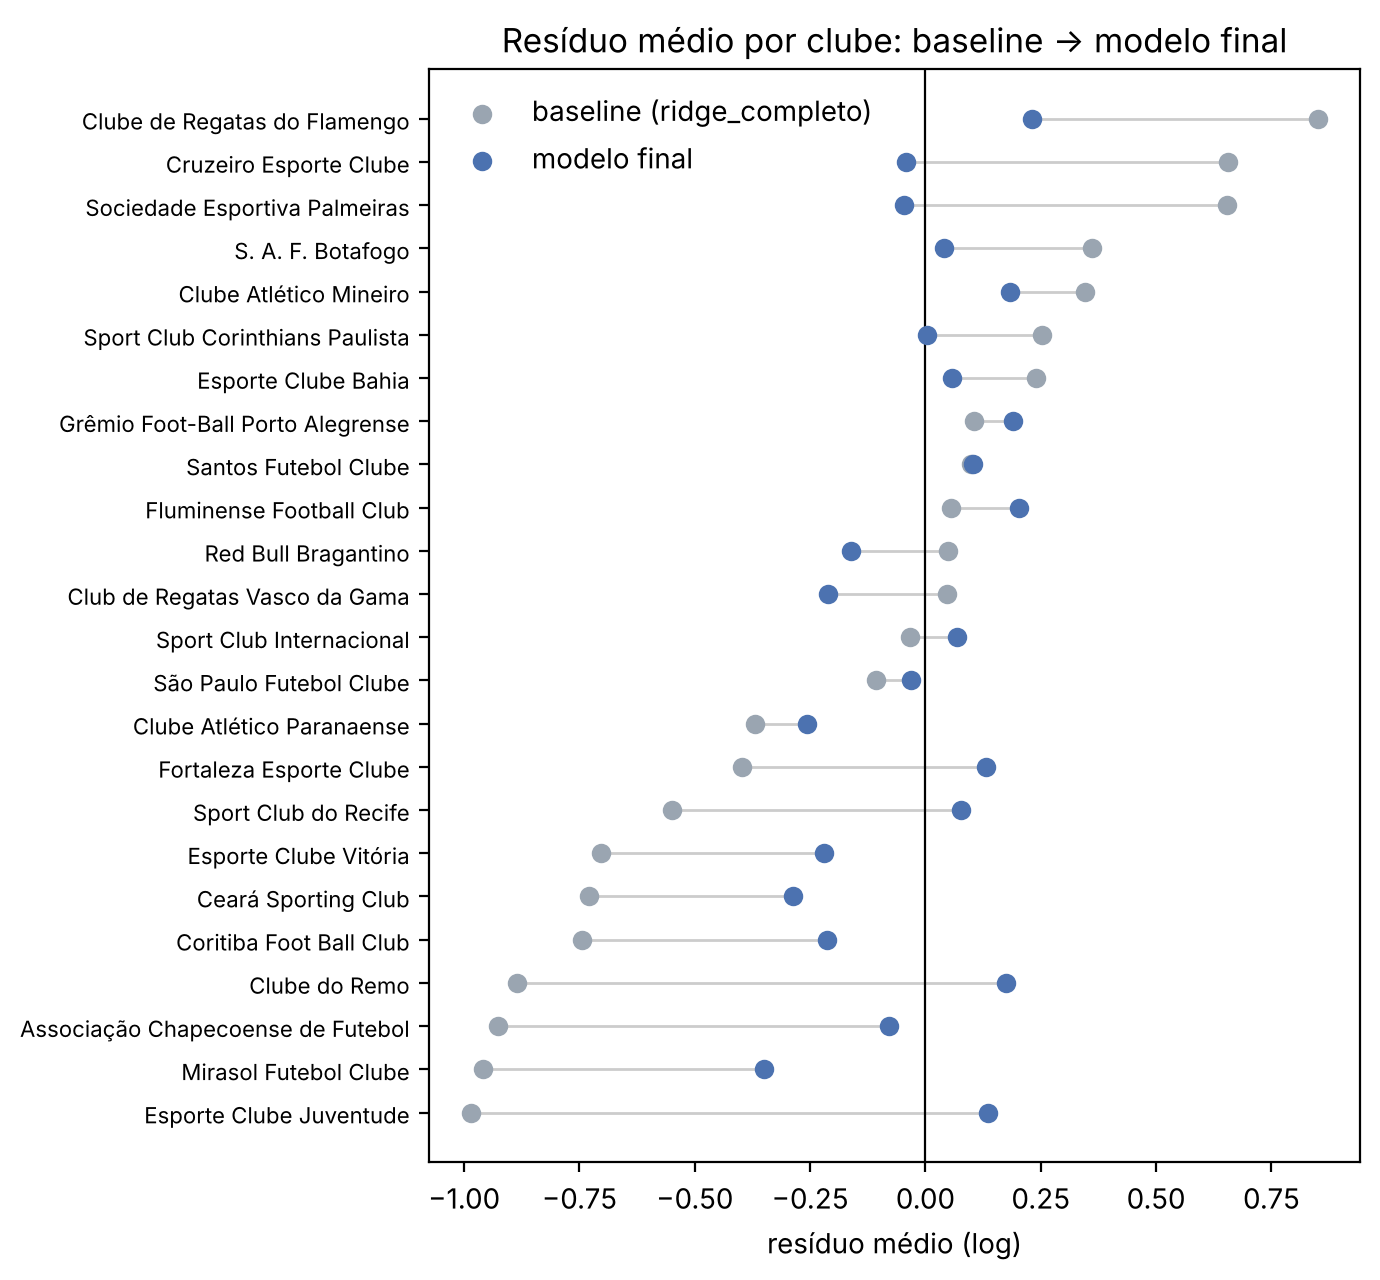

In [5]:
y = np.arange(len(clube))

fig, eixo = plt.subplots(figsize=(7, 6.5))
eixo.scatter(clube["residuo_baseline"], y, color="#9AA5B1", label="baseline (ridge_completo)", zorder=3)
eixo.scatter(clube["residuo_log"], y, color="#4C72B0", label="modelo final", zorder=3)
for i in range(len(clube)):
    eixo.plot([clube["residuo_baseline"].iloc[i], clube["residuo_log"].iloc[i]], [i, i], color="#CCCCCC", linewidth=1, zorder=1)
eixo.axvline(0, color="black", linewidth=0.8)
eixo.set_yticks(y, clube.index, fontsize=8)
eixo.set_xlabel("resíduo médio (log)")
eixo.set_title("Resíduo médio por clube: baseline → modelo final")
eixo.legend(frameon=False)
plt.tight_layout()

fig.savefig("../figuras/residuos_por_clube_baseline_final.png")
plt.show()

- O desvio do resíduo médio entre clubes cai de 0,56 para 0,17: o efeito do clube foi absorvido.
- 2025 continua com resíduo médio positivo (+0,06), por causa do corte de 900 minutos.

## Importância das variáveis

Importância por permutação: em cada fold de teste embaralhamos um bloco de variáveis e medimos quanto o erro (MAE em log) piora. Variáveis que só fazem sentido juntas são embaralhadas juntas (idade + idade², subposições, pé, contrato, participação e força do clube).

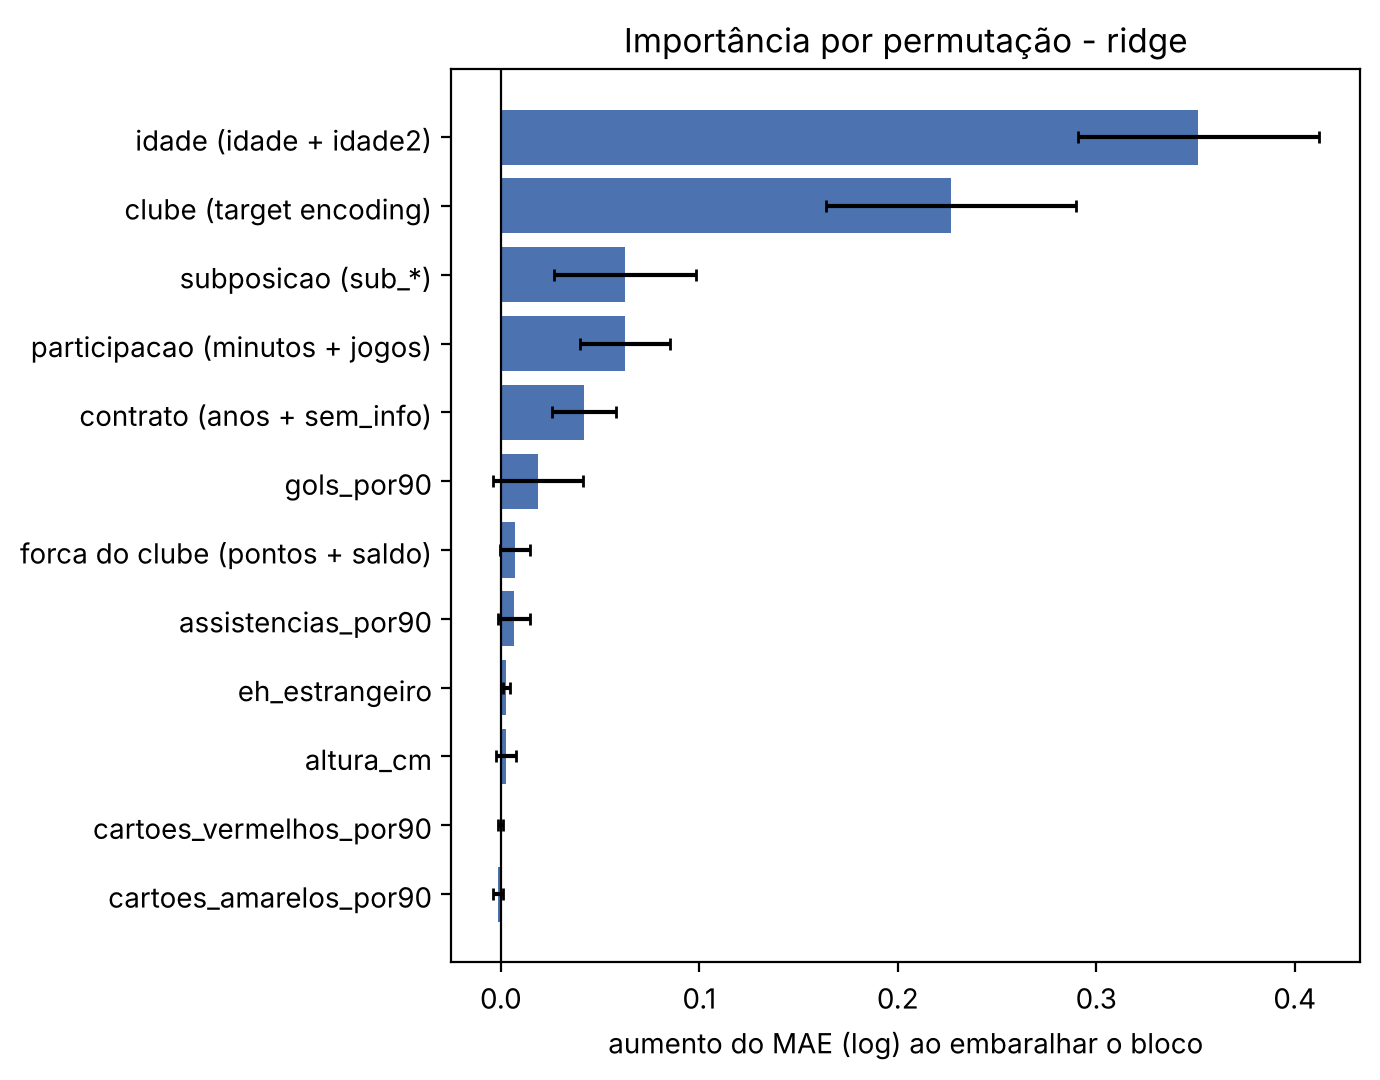

,importancia_media,desvio_entre_folds
idade (idade + idade2),0.3515,0.0606
clube (target encoding),0.2267,0.0630
subposicao (sub_*),0.0625,0.0359
participacao (minutos + jogos),0.0625,0.0226
contrato (anos + sem_info),0.0419,0.0162
gols_por90,0.0187,0.0226
forca do clube (pontos + saldo),0.0070,0.0076
assistencias_por90,0.0065,0.0082
eh_estrangeiro,0.0027,0.0018
altura_cm,0.0027,0.0051


In [6]:
importancia = importancia_permutacao(df, fabrica_final, colunas, blocos=BLOCOS)
importancia.to_csv("../data/processado/importancia_variaveis.csv")

top = importancia.head(12)[::-1]

fig, eixo = plt.subplots(figsize=(7, 5.5))
eixo.barh(top.index, top["importancia_media"], xerr=top["desvio_entre_folds"], color="#4C72B0", capsize=2)
eixo.axvline(0, color="black", linewidth=0.8)
eixo.set_xlabel("aumento do MAE (log) ao embaralhar o bloco")
eixo.set_title(f"Importância por permutação - {nome_final}")
plt.tight_layout()

fig.savefig("../figuras/residuos_importancia_variaveis.png")
plt.show()

importancia.round(4)

- A idade é a que mais pesa, seguida do clube.
- Depois vêm subposição, participação e contrato.
- Gols e assistências por 90 minutos acrescentam pouco, e a força do clube quase nada depois que o clube já está no modelo.

### Direção do efeito

Como o modelo é linear, os coeficientes mostram a direção: positivo aumenta o valor, negativo diminui. As variáveis estão padronizadas, então o coeficiente é o efeito de +1 desvio padrão no log do valor.

`idade` e `idade2` precisam ser lidas juntas (ver a curva de idade). Variáveis correlacionadas, como `participacao_minutos` e `participacao_jogos`, podem sair com sinais opostos porque uma já carrega o efeito da outra.

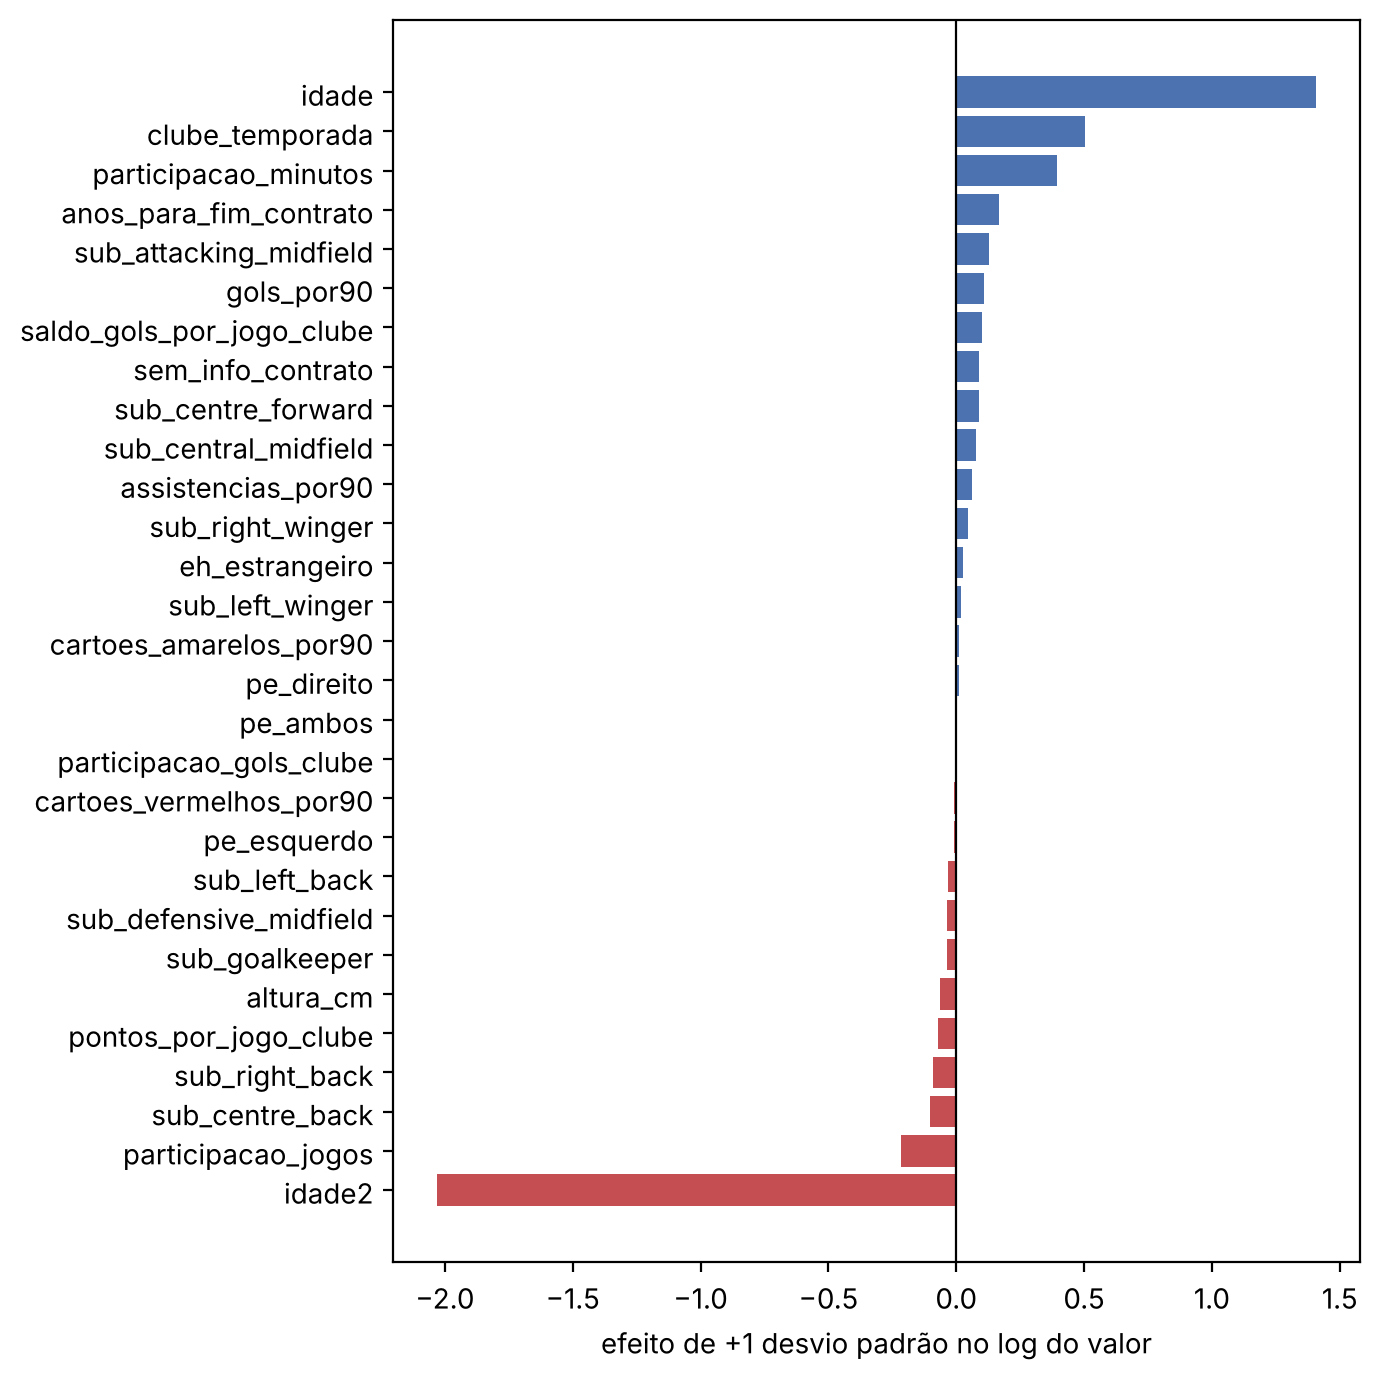

,coeficiente,efeito_pct_aprox
idade2,-2.031,-86.884
participacao_jogos,-0.217,-19.517
sub_centre_back,-0.103,-9.761
sub_right_back,-0.091,-8.663
pontos_por_jogo_clube,-0.073,-7.058
altura_cm,-0.063,-6.130
sub_goalkeeper,-0.037,-3.657
sub_defensive_midfield,-0.036,-3.567
sub_left_back,-0.032,-3.137
pe_esquerdo,-0.011,-1.057


In [7]:
modelo_todo = fabrica_final().fit(df[colunas], df[ALVO])
estimador = modelo_todo[-1]

if hasattr(estimador, "coef_"):
    nomes = modelo_todo[:-1].get_feature_names_out()
    coef = pd.DataFrame({"coeficiente": estimador.coef_, "efeito_pct_aprox": (np.exp(estimador.coef_) - 1) * 100}, index=nomes)
    coef = coef.sort_values("coeficiente")

    fig, eixo = plt.subplots(figsize=(7, 7))
    eixo.barh(coef.index, coef["coeficiente"], color=np.where(coef["coeficiente"] < 0, "#C44E52", "#4C72B0"))
    eixo.axvline(0, color="black", linewidth=0.8)
    eixo.set_xlabel("efeito de +1 desvio padrão no log do valor")
    plt.tight_layout()

    fig.savefig("../figuras/residuos_coeficientes.png")
    plt.show()
    display(coef.round(3))
else:
    print(f"{nome_final} não é linear: use a importância por permutação acima.")

- Contrato mais longo, mais participação em minutos e mais gols aumentam o valor.
- Zagueiros e laterais valem menos; meias ofensivos e centroavantes valem mais.

### Curva de valor por idade

Previsão para um jogador típico (demais variáveis na mediana, subposição mais comum e clube médio), mudando só a idade.

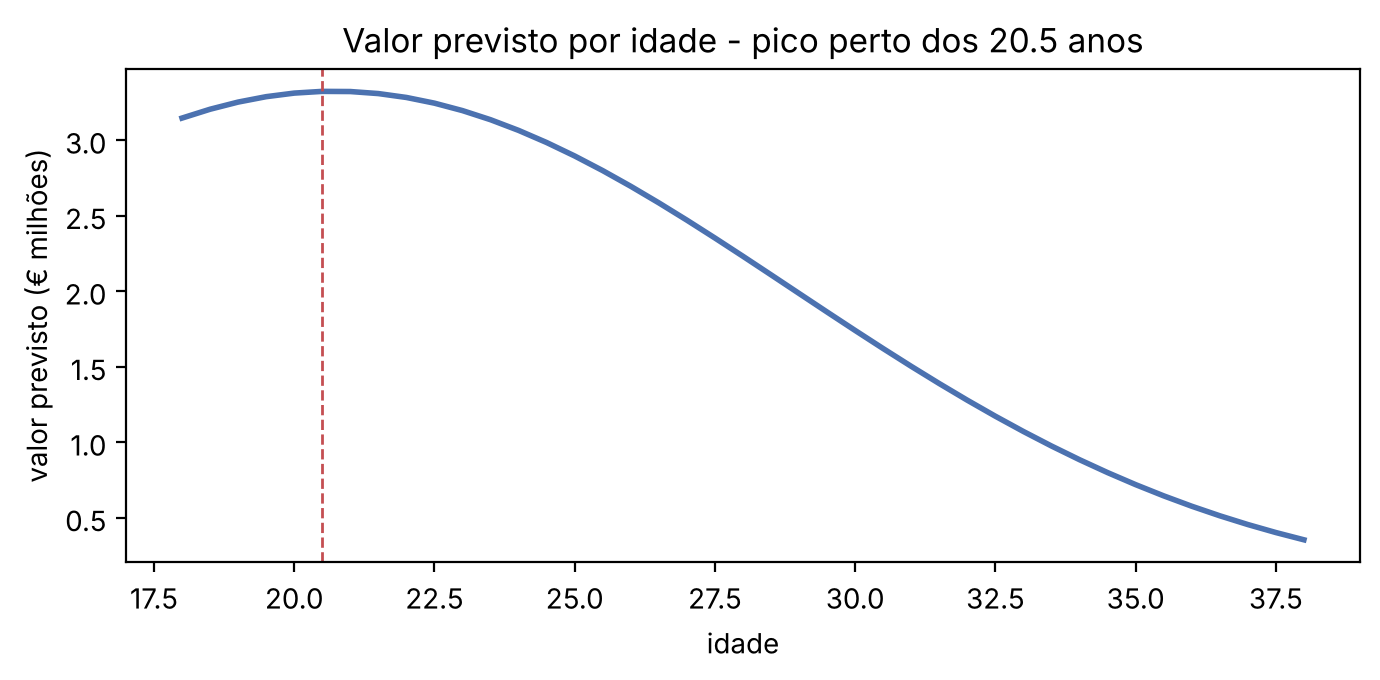

In [8]:
numericas = [c for c in colunas if c != "clube_temporada"]
sub_cols = [c for c in numericas if c.startswith("sub_")]
idades = np.arange(18, 38.5, 0.5)

tipico = pd.DataFrame([df[numericas].median()] * len(idades)).reset_index(drop=True)
tipico[sub_cols] = 0
tipico[df[sub_cols].sum().idxmax()] = 1
tipico["clube_temporada"] = "clube_medio"
tipico["idade"] = idades
tipico["idade2"] = idades ** 2

valor_idade = np.exp(modelo_todo.predict(tipico[colunas]))
pico = idades[valor_idade.argmax()]

fig, eixo = plt.subplots(figsize=(7, 3.5))
eixo.plot(idades, valor_idade / 1e6, color="#4C72B0", linewidth=2)
eixo.axvline(pico, color="#C44E52", linestyle="--", linewidth=1)
eixo.set_xlabel("idade")
eixo.set_ylabel("valor previsto (€ milhões)")
eixo.set_title(f"Valor previsto por idade - pico perto dos {pico:.1f} anos")
plt.tight_layout()

fig.savefig("../figuras/residuos_curva_idade.png")
plt.show()

- O valor cai a partir dos ~20 anos: um jogador típico vale cerca de € 3,3 milhões aos 20 e € 0,7 milhão aos 35.

## Diagnóstico dos resíduos

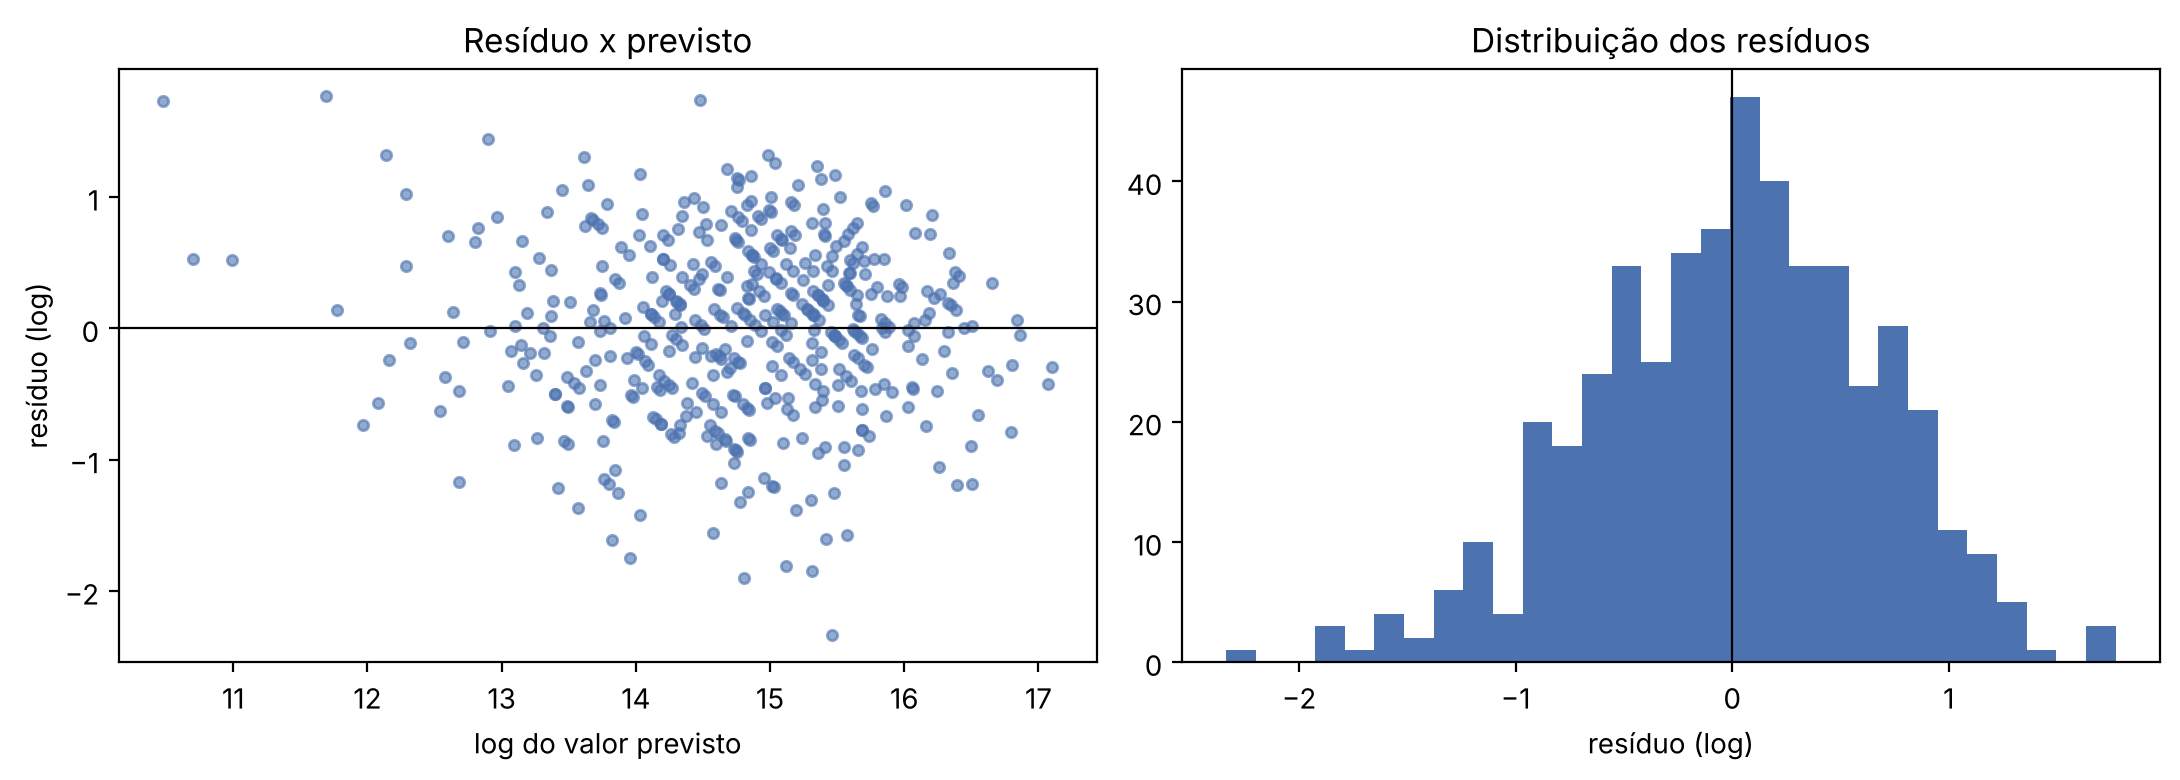

In [9]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
eixos[0].scatter(df["log_previsto"], df["residuo_log"], s=14, alpha=0.6, color="#4C72B0")
eixos[0].axhline(0, color="black", linewidth=0.8)
eixos[0].set_xlabel("log do valor previsto")
eixos[0].set_ylabel("resíduo (log)")
eixos[0].set_title("Resíduo x previsto")

eixos[1].hist(df["residuo_log"], bins=30, color="#4C72B0")
eixos[1].axvline(0, color="black", linewidth=0.8)
eixos[1].set_xlabel("resíduo (log)")
eixos[1].set_title("Distribuição dos resíduos")
plt.tight_layout()

fig.savefig("../figuras/residuos_diagnostico.png")
plt.show()

In [10]:
df["erro_abs_log"] = df["residuo_log"].abs()
df["erro_abs_eur"] = df["residuo_eur"].abs()

for coluna in ["sub_position", "faixa_idade", "season"]:
    resumo = df.groupby(coluna).agg(
        n=("residuo_log", "size"),
        residuo_medio=("residuo_log", "mean"),
        MAE_log=("erro_abs_log", "mean"),
        erro_mediano_eur=("erro_abs_eur", "median"),
    )
    print(f"--- por {coluna}")
    display(resumo.round(3))

--- por sub_position


,n,residuo_medio,MAE_log,erro_mediano_eur
sub_position,,,,
Attacking Midfield,32,-0.011,0.506,1109025.889
Central Midfield,45,-0.047,0.564,1905687.599
Centre-Back,100,0.009,0.579,1004031.957
Centre-Forward,49,0.027,0.480,1012951.301
Defensive Midfield,50,-0.022,0.562,1165638.484
Goalkeeper,39,0.032,0.623,683924.368
Left Winger,36,0.025,0.455,1300821.462
Left-Back,43,-0.022,0.434,954292.118
Right Winger,35,0.048,0.481,1299383.131


--- por faixa_idade


,n,residuo_medio,MAE_log,erro_mediano_eur
faixa_idade,,,,
22_25,91,-0.020,0.521,1973690.146
26_29,164,0.052,0.485,1427791.286
30_33,123,0.008,0.548,1069683.903
34_mais,85,-0.050,0.581,287924.181
ate_21,12,-0.096,0.355,2300639.632


--- por season


,n,residuo_medio,MAE_log,erro_mediano_eur
season,,,,
2024,311,-0.024,0.54,1141434.158
2025,164,0.060,0.49,873315.717


- Os resíduos ficam centrados em zero (média ≈ 0).
- O erro é parecido entre as subposições; é um pouco maior para goleiros e para jogadores com 34 anos ou mais.

## Jogadores sub e supervalorizados

- **Supervalorizado:** o mercado paga mais do que o modelo prevê (resíduo positivo).
- **Subvalorizado:** o mercado paga menos do que o modelo prevê (resíduo negativo).

O limiar é uma diferença de pelo menos 50% entre real e previsto (|resíduo| > log(1,5) ≈ 0,41). Como o clube está no modelo, a comparação é com jogadores de perfil parecido em clubes de peso parecido.

In [11]:
LIMIAR = np.log(1.5)
df["classificacao"] = classificar_residuo(df["residuo_log"], LIMIAR)
print(df["classificacao"].value_counts().to_string())

colunas_saida = ["player_id", "name", "season", "clube_temporada", "posicao", "sub_position", "idade",
                 "valor_mercado_eur", "valor_previsto_eur", "residuo_eur", "residuo_log",
                 "razao_real_previsto", "classificacao"]
residuos = df[colunas_saida].sort_values("residuo_log", ascending=False).reset_index(drop=True)
residuos.to_csv("../data/processado/residuos_jogadores.csv", index=False)

classificacao
dentro_do_esperado    214
supervalorizado       133
subvalorizado         128


In [12]:
mostrar = ["name", "season", "clube_temporada", "sub_position", "idade", "valor_mercado_eur", "valor_previsto_eur", "razao_real_previsto"]

print("Top 10 SUPERVALORIZADOS (mercado paga mais do que o modelo prevê)")
display(residuos[mostrar].head(10).round(2))
print("Top 10 SUBVALORIZADOS (modelo prevê mais do que o mercado paga)")
display(residuos[mostrar].tail(10).sort_values("razao_real_previsto").round(2))

Top 10 SUPERVALORIZADOS (mercado paga mais do que o modelo prevê)


,name,season,clube_temporada,sub_position,idade,valor_mercado_eur,valor_previsto_eur,razao_real_previsto
0,Thiago Silva,2024,Fluminense Football Club,Centre-Back,40.9,700000.0,119245.79,5.87
1,Neymar,2024,Santos Futebol Clube,Attacking Midfield,33.6,11000000.0,1939816.41,5.67
2,Nenê,2024,Esporte Clube Juventude,Attacking Midfield,44.1,200000.0,35479.07,5.64
3,Pedro Henrique,2024,Ceará Sporting Club,Right Winger,35.2,1700000.0,400616.87,4.24
4,Gilberto,2024,Esporte Clube Juventude,Centre-Forward,36.2,700000.0,186694.14,3.75
5,Gabriel Brazão,2025,Santos Futebol Clube,Goalkeeper,25.5,12000000.0,3211724.98,3.74
6,Sergio Rochet,2024,Sport Club Internacional,Goalkeeper,32.4,3000000.0,815091.42,3.68
7,Fabrício Bruno,2025,Cruzeiro Esporte Clube,Centre-Back,30.1,12000000.0,3395333.65,3.53
8,Martinelli,2025,Fluminense Football Club,Defensive Midfield,24.4,16000000.0,4643988.17,3.45
9,Mathías Villasanti,2024,Grêmio Foot-Ball Porto Alegrense,Defensive Midfield,28.4,8000000.0,2377745.05,3.36


Top 10 SUBVALORIZADOS (modelo prevê mais do que o mercado paga)


,name,season,clube_temporada,sub_position,idade,valor_mercado_eur,valor_previsto_eur,razao_real_previsto
474,Cauan Barros,2024,Club de Regatas Vasco da Gama,Defensive Midfield,21.4,500000.0,5172147.40,0.10
473,Jemmes,2024,Mirasol Futebol Clube,Centre-Back,25.3,400000.0,2683842.77,0.15
472,Lucas Silva,2024,Cruzeiro Esporte Clube,Defensive Midfield,32.5,700000.0,4455592.59,0.16
471,Stiven Mendoza,2025,Clube Atlético Paranaense,Left Winger,33.8,600000.0,3669009.94,0.16
470,Bruno,2024,Ceará Sporting Club,Goalkeeper,31.5,200000.0,1152484.48,0.17
469,Wilker Ángel,2024,Esporte Clube Juventude,Centre-Back,32.4,200000.0,1005475.35,0.20
468,Tchoca,2024,Sport Club Corinthians Paulista,Centre-Back,21.7,1000000.0,4965035.30,0.20
467,Alan Saldivia,2025,Club de Regatas Vasco da Gama,Centre-Back,24.0,1200000.0,5804182.61,0.21
466,Marcos Victor,2024,Ceará Sporting Club,Centre-Back,23.8,450000.0,2137487.25,0.21
465,Lucas Mugni,2024,Ceará Sporting Club,Attacking Midfield,33.6,300000.0,1242521.50,0.24


- 214 jogadores ficam dentro do esperado, 133 supervalorizados e 128 subvalorizados.
- Entre os supervalorizados aparecem veteranos com muita reputação (Thiago Silva, Neymar, Nenê), algo que a base não mede.
- Entre os subvalorizados aparecem jogadores com valor baixo para o perfil e o clube, como Cauan Barros (Vasco) e Jemmes (Mirassol).
- Supervalorizado não quer dizer que o preço está errado, e sim que existe algo fora da base (reputação, seleção, potencial de venda).

## O resíduo é do jogador ou da temporada?

117 jogadores aparecem nas duas temporadas. Se o resíduo se repete, existe um fator do próprio jogador que o modelo não capta.

Jogadores nas duas temporadas: 117
Correlação do resíduo 2024 x 2025: 0.64
Mesmo sinal nas duas temporadas: 74%


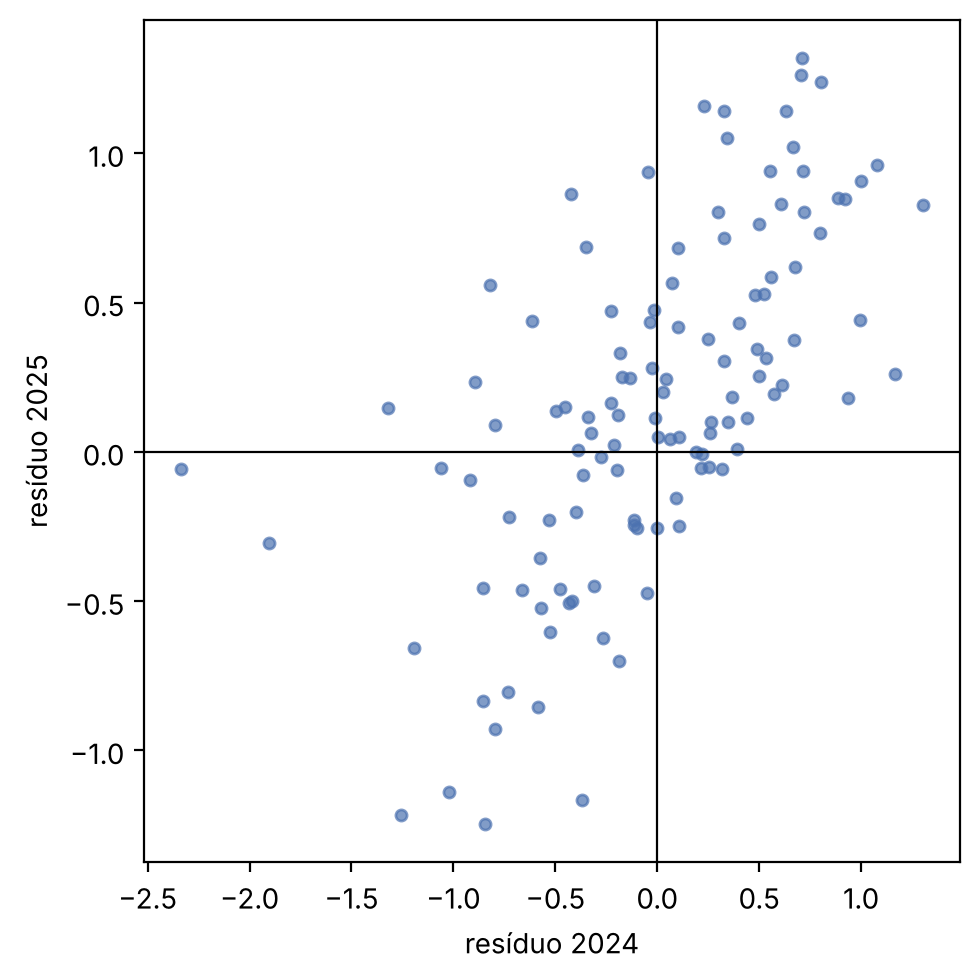

In [13]:
pivo = df.pivot_table(index="player_id", columns="season", values="residuo_log").dropna()
t1, t2 = pivo.columns

print(f"Jogadores nas duas temporadas: {len(pivo)}")
print(f"Correlação do resíduo {t1} x {t2}: {pivo[t1].corr(pivo[t2]):.2f}")
print(f"Mesmo sinal nas duas temporadas: {(np.sign(pivo[t1]) == np.sign(pivo[t2])).mean():.0%}")

fig, eixo = plt.subplots(figsize=(5, 5))
eixo.scatter(pivo[t1], pivo[t2], s=16, alpha=0.7, color="#4C72B0")
eixo.axhline(0, color="black", linewidth=0.8)
eixo.axvline(0, color="black", linewidth=0.8)
eixo.set_xlabel(f"resíduo {t1}")
eixo.set_ylabel(f"resíduo {t2}")
plt.tight_layout()

fig.savefig("../figuras/residuos_entre_temporadas.png")
plt.show()

- A correlação do resíduo entre 2024 e 2025 é de 0,64, e 74% dos jogadores mantêm o mesmo sinal.
- Ou seja, boa parte do resíduo é do jogador e não ruído da temporada: existe um "efeito jogador" que a base não tem.

## Conclusões

- Idade e clube explicam a maior parte do valor; o desempenho em campo acrescenta pouco.
- O efeito do clube foi absorvido pelo modelo.
- Os jogadores fora da curva são, em boa parte, casos de reputação ou de fatores fora da base.